# Multi-Fidelity Method Comparison: Shifted Peaks Function
Example is based on the peaks function with a shifted low fidelity function for multi-fidelity purposes

In [1]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import torch
import numpy as np

from SurrogateModels import mfsnn, cokriging, mfkans
import multi_fidelity_functions

Introduce the example function

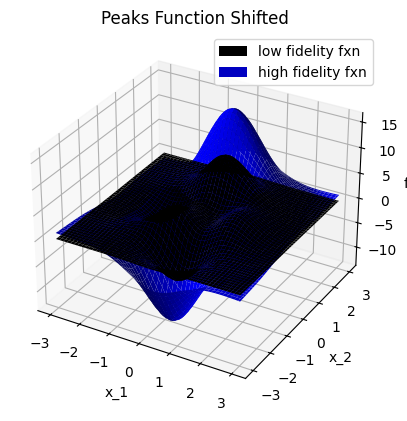

In [2]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.PeaksShifted()
mf_example.plot_functions(name=mf_example.name)
plt.legend()
plt.grid()
plt.show()

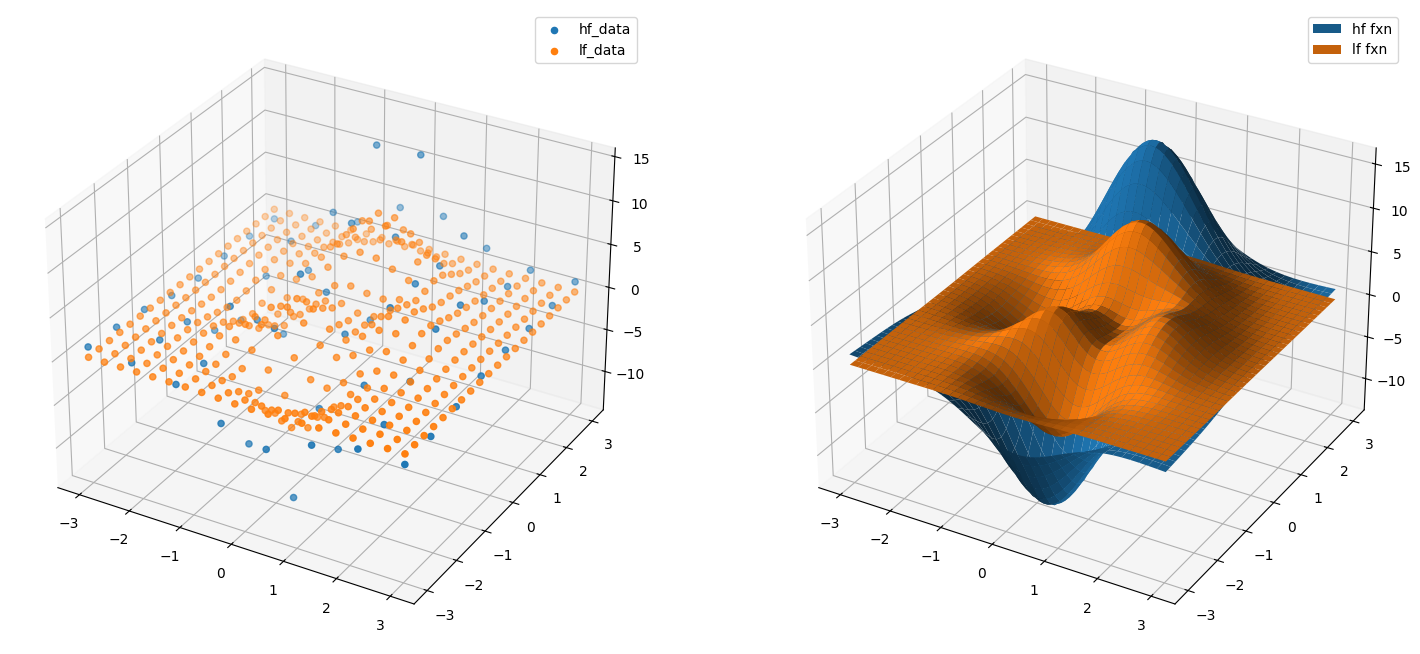

In [3]:
import multi_fidelity_functions as mff
import matplotlib.pyplot as plt
from SurrogateModels import cokriging, model

n_hf = 8
n_lf = 20
n_samp = 75

mf_example = mff.PeaksShifted()

bounds = mf_example.bounds
x1min = bounds[0][0]
x1max = bounds[0][1]
x2min = bounds[1][0]
x2max = bounds[1][1]

X_hf = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_hf)
X_lf = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_lf)
y_hf = mf_example.high_fidelity(X_hf)
y_lf = mf_example.low_fidelity(X_lf)

# take samples for plotting ground truth function
X_test = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_samp)
y_hf_test = mf_example.high_fidelity(X_test)
y_lf_test = mf_example.low_fidelity(X_test)

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(121, projection="3d")

sc = ax.scatter(X_hf[:, 0], X_hf[:, 1],y_hf[:,0], label="hf_data")
sc = ax.scatter(X_lf[:, 0], X_lf[:, 1],y_lf[:,0], label="lf_data")
ax.legend()

#Plot the actual surfaces of the lf and hf functions

X1, X2 = model.Model.generate_grid(x1min, x1max, x2min, x2max, n_samp)
y_samp_hf = y_hf_test.reshape(n_samp,n_samp)
y_samp_lf = y_lf_test.reshape(n_samp,n_samp)

ax = fig.add_subplot(122, projection="3d")
ax.plot_surface(X1, X2, y_samp_hf,label="hf fxn")
ax.plot_surface(X1, X2, y_samp_lf,label="lf fxn")
ax.legend()

plt.show()

## Multi-Fidelity Neural Network Fit

Using the method outlined by Meng and Karniadakis in the 2020 paper 
"A composite neural network that learns from multi-fidelity data: Application to function approximation and inverse PDE problems"
 generate a multi-fidelity function fit using the data defined from the analytical functions.

In [4]:
mfnn_model = mfsnn.MultiFidelityNN(
    X_lf=X_lf,
    y_lf=y_lf,
    X_lf_test=X_test,
    y_lf_test=y_lf_test,
    X_hf=X_hf,
    y_hf=y_hf,
    X_hf_test=X_test,
    y_hf_test=y_hf_test,
    lf_nn_dim=[20, 20, 20],
    hf_nl_nn_dim=[10, 10, 10],
    epochs_lf=100,
    epochs_mf=1000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf=0.01,
    wd_mf=0.01,
)

Epoch: 0   || Train Error: 0.008344834670424461 || Test Error: 0.0002955714880954474

Epoch: 1   || Train Error: 0.0027989486698061228 || Test Error: 8.600885485066101e-05

Epoch: 2   || Train Error: 0.0018334253691136837 || Test Error: 3.754421777557582e-05

Epoch: 3   || Train Error: 0.002754503395408392 || Test Error: 2.7001566195394844e-05

Epoch: 4   || Train Error: 0.0013588630827143788 || Test Error: 2.2048765458748676e-05

Epoch: 5   || Train Error: 0.0007694495725445449 || Test Error: 3.109085446340032e-05

Epoch: 6   || Train Error: 0.0005871275207027793 || Test Error: 7.135160558391362e-05

Epoch: 7   || Train Error: 0.0004178528906777501 || Test Error: 6.635545287281275e-05

Epoch: 8   || Train Error: 0.00033460461418144405 || Test Error: 2.788540587062016e-05

Epoch: 9   || Train Error: 0.00016490336565766484 || Test Error: 7.976486813277006e-06

Epoch: 10   || Train Error: 0.0001732233358779922 || Test Error: 3.7710537981183734e-06

Epoch: 11   || Train Error: 0.000134412

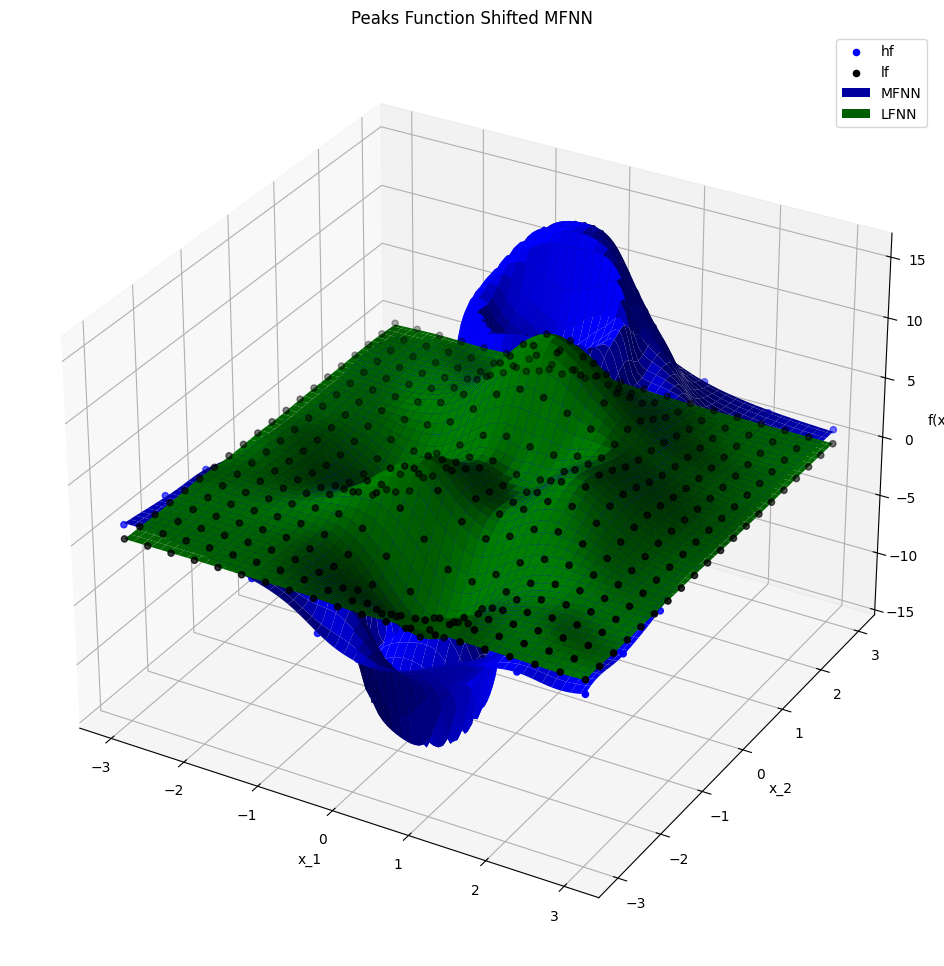

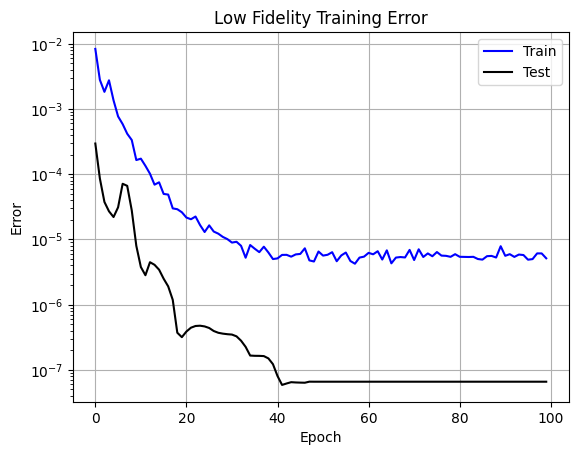

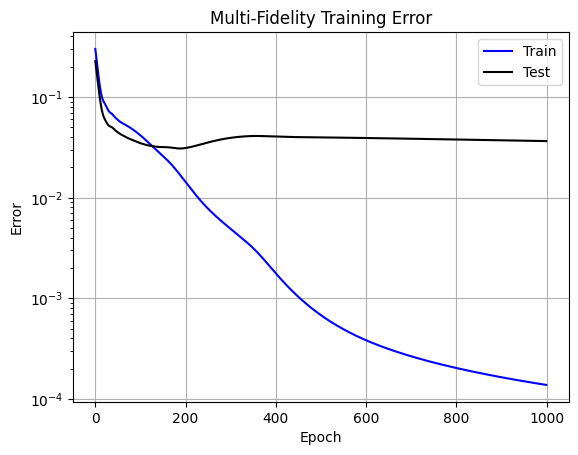

In [5]:
# Plot the results
plot_name = mf_example.name + " MFNN"

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(111, projection="3d")

ax = mfnn_model.plot_data(plot_name, ax= ax)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MFNN",
    linestyle="solid",
    ax=ax,
)
ax = mfnn_model.low_fidelity_nn.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="LFNN",
    linestyle="solid",
    ax=ax,
)
#ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Plot the model error
mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()
mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()

## Co-Kriging Function Fit

Utilizes the Co-Kriging function fit outlined in the Forrester 2007 paper.

In [6]:
cokriging_model = cokriging.CoKriging(X_lf, y_lf, X_hf, y_hf)

C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:91: RuntimeWarning: divide by zero encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))
c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\scipy\optimize\_numdiff.py:592: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0


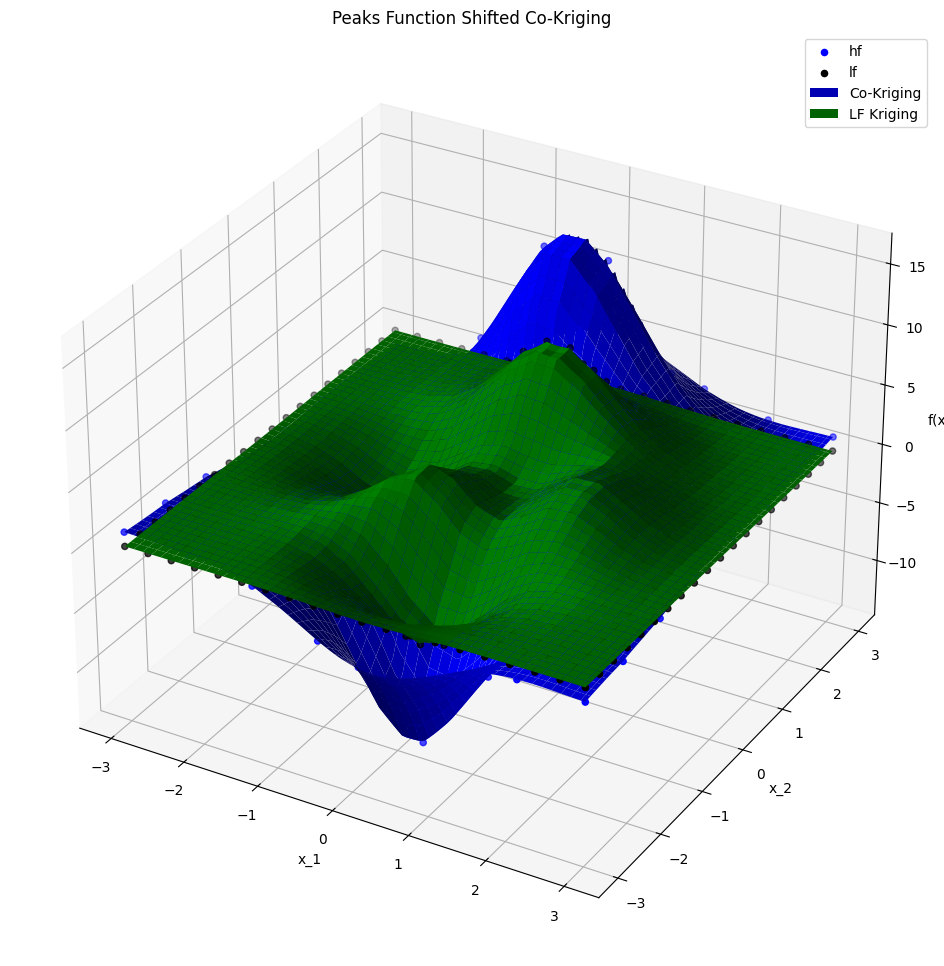

In [7]:
# Plot the results
plot_name = mf_example.name + " Co-Kriging"

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(111, projection="3d")

ax = cokriging_model.plot_data(plot_name, ax=ax)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="Co-Kriging",
    linestyle="solid",
    ax=ax,
)
ax = cokriging_model.kriging_lf.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF Kriging",
    color="green",
    linestyle="solid",
    ax=ax,
)
#ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

### MFKAN Model
Sets up a MFKAN model for a 1D dataset

In [ ]:
# MFKAN Model for forrester mf example
mfkan_model = mfkans.MFKANModel(
    x_lf=X_lf,
    y_lf=y_lf,
    x_lf_test=X_test,
    y_lf_test=y_lf_test,
    x_hf=X_hf,
    y_hf=y_hf,
    x_hf_test=X_test,
    y_hf_test=y_hf_test,
    spline_order_lf=3,
    spline_order_mf=2,
    width_lf=[2, 4, 1],
    width_mf=[3, 1, 1],
    grid_lf=[3, 5, 10],
    grid_mf=[3, 5, 10],
    opt_lf="LBFGS",
    opt_mf="LBFGS",
    n_iter_lf=50,
    n_iter_mf=50,
)

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 2.87e-01 | test_loss: 2.92e-01 | reg: 2.03e+01 | : 100%|█| 50/50 [00:20<00:00,  2.45it


saving model version 0.1
saving model version 0.2


| train_loss: 1.97e-01 | test_loss: 2.01e-01 | reg: 2.19e+01 | : 100%|█| 50/50 [00:46<00:00,  1.08it


saving model version 0.3
saving model version 0.4


| train_loss: 9.05e-02 | test_loss: 9.14e-02 | reg: 2.31e+01 | : 100%|█| 50/50 [00:56<00:00,  1.13s/


... (3 outputs left out)

| train_loss: 2.02e+00 | test_loss: 2.10e+00 | reg: 5.76e+01 | : 100%|█| 50/50 [00:21<00:00,  2.35it


saving model version 0.3
saving model version 0.4
Does it make it here?


| train_loss: 1.86e+00 | test_loss: 2.09e+00 | reg: 1.02e+02 | : 100%|█| 50/50 [00:21<00:00,  2.35it

saving model version 0.5


c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


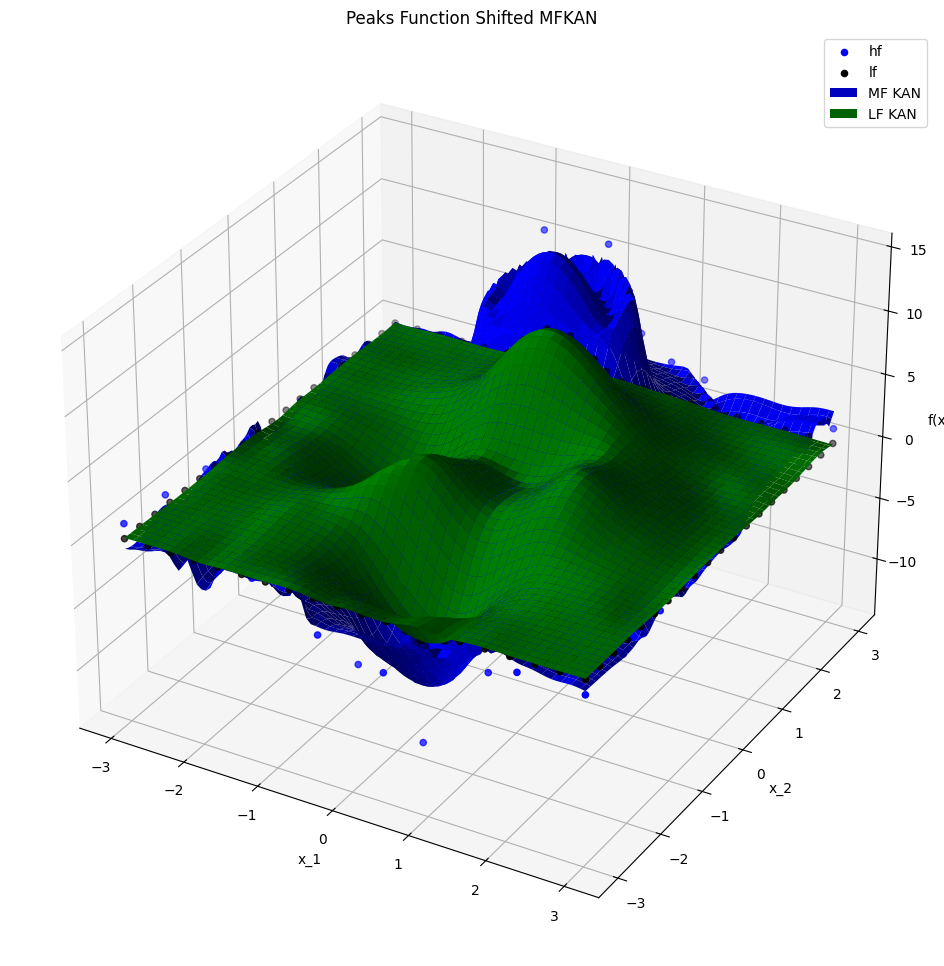

In [9]:
# Plot the results
plot_name = mf_example.name + " MFKAN"

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(111, projection="3d")

ax = mfkan_model.plot_data(plot_name,ax=ax)
ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="solid",
    ax=ax,
)
ax = mfkan_model.lf_kan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF KAN",
    color="green",
    linestyle="solid",
    ax=ax,
)
#ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Model Comparison

Compare the three different methods for their ability to fit the high fidelity function.

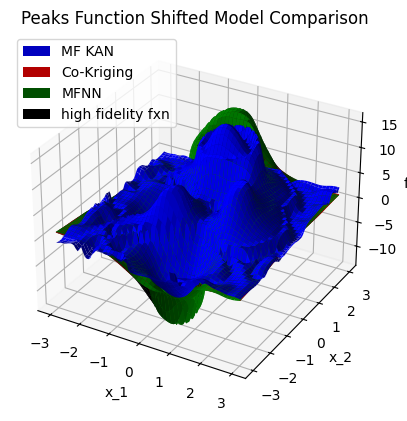

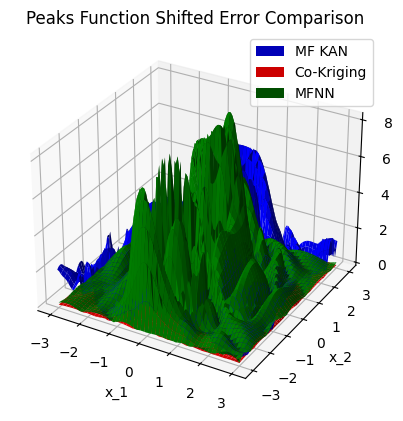

In [10]:
plot_name = mf_example.name + " Model Comparison"

ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
ax = mf_example.plot_high_fidelity(
    name=plot_name, linestyle="solid", color="black", ax=ax
)
plt.legend()
plt.grid()
plt.show()

plot_name = mf_example.name + " Error Comparison"

ax = mfkan_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
)
ax = cokriging_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
plt.legend()
plt.grid()
plt.show()